# DL088 完整实验回放
双编码器：严格配对与语义检索。主实验9模型，另2次温度诊断。本Notebook真实重训到notebook_run，不覆盖发行outputs。CPU NumPy、合成数据、无需网络。

In [1]:
from pathlib import Path
import json, numpy as np
import experiment as exp
original_root = exp.ROOT
print("NumPy", np.__version__)

NumPy 2.3.5


## 数据与输入边界
先检查shape，再运行优化。评价真值不能作为预测输入。

In [2]:
d = exp.make_data(4, 8801)
print({k: v.shape for k, v in d.items()})
print(d["captions"][:4])
print("parameters", sum(v.size for v in exp.initial(11).values()))

{'x': (72, 192), 't': (72, 10), 'y': (72,), 'captions': (72,)}
['there is a green horizontal on the right'
 'there is a blue vertical on the left' 'a blue square on the left'
 'there is a red horizontal on the right']
parameters 3232


## 手算与梯度核验
有限差分支持局部导数；它不替代数据切分和研究设计审查。

In [3]:
s = np.array([[2., 0.], [1., 0.]])
li = -np.log(np.diag(exp.softmax(s, 1))).mean()
lt = -np.log(np.diag(exp.softmax(s, 0))).mean()
print("row loss, column loss, symmetric:", li, lt, (li+lt)/2)
print("gradient check", exp.finite_difference())

row loss, column loss, symmetric: 0.7200948492805977 0.503204434039084 0.6116496416598409
gradient check {'image_to_text': np.float64(2.750445704524651e-11), 'symmetric': np.float64(3.359623690357694e-11), 'semantic_multi_positive': np.float64(2.3567092721776817e-11)}


## 从随机初始化完整重训
固定全部方法、种子与更新步数。新结果写入独立子目录。

In [4]:
run_root = original_root / "notebook_run"
run_root.mkdir(exist_ok=True)
exp.ROOT = run_root
try:
    result = exp.main()
finally:
    exp.ROOT = original_root

{
  "audit": {
    "exact_image_overlap": 0,
    "unique_train_captions": 36,
    "caption_overlap_across_splits": 36,
    "off_diagonal_semantic_positive_count": 9936,
    "off_diagonal_count": 186192,
    "semantic_false_negative_fraction": 0.05336426914153132,
    "cross_split_max_image_cosine": 0.8860434173052673,
    "cross_split_mean_nearest_image_cosine": 0.8430716629243272,
    "meaning": "Caption reuse is expected: independent image instances share semantic labels. No instance-ID signal is supplied."
  },
  "gradient_check": {
    "image_to_text": 2.750445704524651e-11,
    "symmetric": 3.359623690357694e-11,
    "semantic_multi_positive": 2.3567092721776817e-11
  },
  "mean_recall": {
    "image_to_text": {
      "i2t_pair_r1": 0.09413580246913582,
      "i2t_semantic_r1": 0.9953703703703703,
      "t2i_pair_r1": 0.05864197530864198,
      "t2i_semantic_r1": 1.0
    },
    "symmetric": {
      "i2t_pair_r1": 0.09722222222222221,
      "i2t_semantic_r1": 0.9938271604938271,
  

## 从本次运行重算结果
不读取发行汇总表冒充Notebook运行。

In [5]:
for method in exp.METHODS:
    rows = [r for r in result["records"] if r["method"] == method]
    print(method, {k: float(np.mean([r[k] for r in rows])) for k in ["i2t_pair_r1", "i2t_semantic_r1", "t2i_pair_r1", "t2i_semantic_r1"]})
print("audit", result["audit"])

image_to_text {'i2t_pair_r1': 0.09413580246913582, 'i2t_semantic_r1': 0.9953703703703703, 't2i_pair_r1': 0.05864197530864198, 't2i_semantic_r1': 1.0}
symmetric {'i2t_pair_r1': 0.09722222222222221, 'i2t_semantic_r1': 0.9938271604938271, 't2i_pair_r1': 0.060185185185185175, 't2i_semantic_r1': 1.0}
semantic_multi_positive {'i2t_pair_r1': 0.0787037037037037, 'i2t_semantic_r1': 1.0, 't2i_pair_r1': 0.0787037037037037, 't2i_semantic_r1': 1.0}
audit {'exact_image_overlap': 0, 'unique_train_captions': 36, 'caption_overlap_across_splits': 36, 'off_diagonal_semantic_positive_count': 9936, 'off_diagonal_count': 186192, 'semantic_false_negative_fraction': 0.05336426914153132, 'cross_split_max_image_cosine': 0.8860434173052673, 'cross_split_mean_nearest_image_cosine': 0.8430716629243272, 'meaning': 'Caption reuse is expected: independent image instances share semantic labels. No instance-ID signal is supplied.'}


## 对研究假设做检查

In [6]:
print("false-negative rate", 23/431)
print("expected same-class competitors", 71*23/431)
print("Every primary checkpoint reload error:", [r["reload_max_error"] for r in result["records"]])

false-negative rate 0.05336426914153132
expected same-class competitors 3.788863109048724
Every primary checkpoint reload error: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


## 全部自动测试
测试失败会中止回放，而不是继续绘制看起来成功的结果。

In [7]:
import unittest
suite = unittest.defaultTestLoader.discover(str(original_root), pattern="test_experiment.py")
check = unittest.TextTestRunner(verbosity=2).run(suite)
if not check.wasSuccessful():
    raise RuntimeError("test failure")

test_both_towers_update (test_experiment.TestAlignment.test_both_towers_update) ... 

ok


test_exact_losses (test_experiment.TestAlignment.test_exact_losses) ... 

ok


test_false_negative_count (test_experiment.TestAlignment.test_false_negative_count) ... 

...

test_stable_ties (test_experiment.TestAlignment.test_stable_ties) ... 

ok


test_text_attribute_groups (test_experiment.TestAlignment.test_text_attribute_groups) ... 

ok


----------------------------------------------------------------------
Ran 15 tests in 0.045s

OK


## 显示本次真实训练图表
PNG直接嵌入输出，离线打开Notebook也可看图。

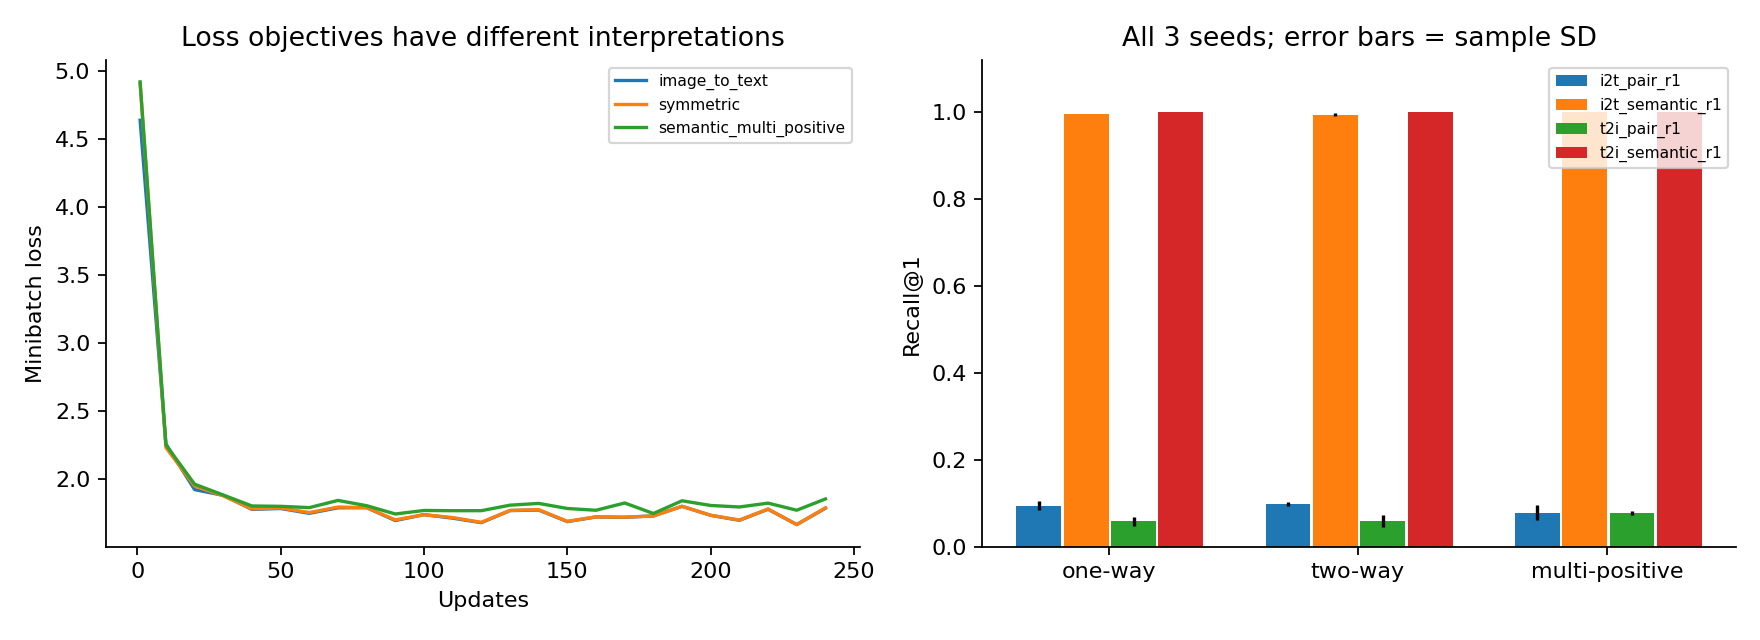

In [8]:
from IPython.display import display, Image
display(Image(filename=str(run_root / "figures" / "04_training_retrieval.png")))

## 写下结论
记录一个受证据支持的发现、一个不支持的预设、一个不能外推的能力。对照lecture.md、lab.md和answers.md，不把教学小模型称为大型VLM复现。